# Ca broadband focusing — formal retake

Import the measurements, **manually align each wavelength using two clicked lens points**, then select a height and construct the publication figure. Change `ION_INDEX` to `"M1"` or `"P1"` and run the sections in order. The manual-alignment cell opens a desktop window for each wavelength that has no saved selection.

All six wavelength slots stay in order: **405, 450, 515, 635, 729, 880 nm**. Adding the missing wavelength folders and rerunning discovery includes them automatically. Raw data stay in Google Drive; import, alignment, and plotting logic live in `Analysis/ca_3d_import.py` and `Analysis/ca_3d_plotting.py` in this repository. Saved manual selections and figure exports stay inside `Gen_1_Paper`.

Full intensity stacks are optional. Height plotting reads only the selected source TIFF and applies that wavelength's manual rotation, so changing heights does not require rotating the entire scan.

In [8]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
# Opaque white canvas keeps labels visible in dark notebook themes.
plt.rcParams.update({
    "figure.facecolor": "white", "figure.edgecolor": "white",
    "axes.facecolor": "white", "savefig.facecolor": "white",
    "savefig.edgecolor": "white", "savefig.transparent": False,
    "text.color": "black", "axes.labelcolor": "black",
    "axes.edgecolor": "black", "xtick.color": "black", "ytick.color": "black",
})


# Works when launched from the repo root or Gen_1_Paper (or a subfolder).
PROJECT_ROOT = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "Analysis" / "ca_3d_import.py").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise RuntimeError("Launch this notebook from inside the integrated_trapped_ions repository.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from Analysis.ca_3d_import import (
    WAVELENGTHS_NM, discover_ca_scans, summarize_ca_scans,
)
from Analysis.ca_3d_plotting import (
    align_scans_manual, preview_alignments, select_height_plane,
    plot_publication_grid, export_publication,
)

## Import settings

`STAGE_TO_HEIGHT_RATIO = 0.5`: 2 µm of stage motion gives 1 µm of height. Each wavelength has its own focused position at height zero. Positive stage Z gives positive height.

In [9]:
DATA_ROOT = Path(
    "/Users/yiyangzhi/Library/CloudStorage/GoogleDrive-yiyang_zhi3@berkeley.edu/"
    "My Drive/Ming Wu Integrated Photonics Group/Experiments/Measurements/"
    "Gen1_Paper/Gen1_Paper_Formal_Retake/Ca_3D"
)
ION_INDEX = "M1"  # Choose "M1" or "P1" here.
STAGE_TO_HEIGHT_RATIO = 0.5  # Physical height travel / stage travel.
LOAD_FULL_STACKS = True  # True loads all measured wavelengths (~2 GB for one ion).


## Discover measurements and import the logs

The loader checks that every logged filename has a TIFF, every TIFF has a log entry, indices and filenames are unique, and exposures are positive. Frames are sorted by numeric `image_index`; recorded exposure and stage position remain attached to their own frame.

In [10]:
scans = discover_ca_scans(
    DATA_ROOT, ION_INDEX, stage_to_height_ratio=STAGE_TO_HEIGHT_RATIO,
)
inventory = summarize_ca_scans(scans)
display(inventory)
print(f"Ion {ION_INDEX}: {sum(s is not None for s in scans.values())}/6 wavelengths available.")

,wavelength_nm,status,frames,height_min_um,height_max_um,median_height_step_um,exposure_min_ms,exposure_max_ms,focus_stage_mm,reference
0,405,available,88,1.0025,87.9260,0.999,1.864980,10.071794,0.990987,focused_20261108_133724_180379_48adc2.tiff
1,450,not measured,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,515,not measured,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,635,not measured,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,729,available,150,0.9990,149.8715,0.999,0.796141,20.902864,0.993000,focused_20261108_121841_181460_e9b90f.tiff
5,880,available,150,1.0025,149.8715,0.999,13.889277,66.620912,0.991990,focused_20261108_124736_202754_f7d46a.tiff


Ion M1: 3/6 wavelengths available.


## Data structure and coordinates

```text
Ca_3D/
  ion_M1/                         # or ion_P1/
    405_nm/                       # also 450, 515, 635, 729, 880 when measured
      focused_<timestamp>_<id>.tiff
      focused_<timestamp>_<id>.json
      focused_<timestamp>_<id>_preview.png
      height_scan/
        NA0.55_Magnification50_000.tiff
        NA0.55_Magnification50_001.tiff
        ...
        exposure_log.csv
```

The log columns are `image_index`, `stage_position_mm`, `exposure_ms`, `max_intensity_8bit`, and `filename`. The JSON retains focus history, exposure, ROI, and `focus_state.result.final_z_mm`. The ROI describes autofocus selection; the observed TIFFs are full **1024 × 1280 × 3 RGB** images. The PNG is a preview; analysis reads the original TIFF.

`height_um = (stage_position_mm − focus_stage_mm) × 1000 × 0.5`

The first captured frame is about 1 µm above focus, and subsequent frames are about 1 µm apart after the stage ratio. Heights retain readback precision rather than being rounded. The current 405 nm scans are shorter than the 729/880 nm scans, so each wavelength retains its own heights and frame count.

| Object | Contents |
| --- | --- |
| `scans[405]` | `CaHeightScan` for the chosen ion; unmeasured slots such as `scans[450]` are `None` |
| `scans[405].frames` | DataFrame with original log columns plus TIFF `path` and calibrated `height_um` |
| `scans[405].reference_metadata` | Complete focused-image JSON |
| `white_light[405]` | Original reference pixels `[row, column, channel]`, no rotation |
| `sample_frames[405]` | First scan frame, original pixels and dtype |
| `intensity[405]` | Optional float32 stack `[frame, row, column]`, raw R+G+B counts |

The keys of `scans`, `white_light`, `sample_frames`, and `intensity` always include all six wavelengths. A `None` value indicates an unmeasured wavelength, or a stack that has not been loaded. Frame indices are acquisition labels, not heights. Rows increase downward and columns rightward; physical image axes are defined by the manual lens alignment below.

In [11]:
# Show an example log with the derived physical heights.
example_wavelength = next((wl for wl, scan in scans.items() if scan is not None), None)
if example_wavelength is not None:
    example = scans[example_wavelength]
    print(f"Example: ion {ION_INDEX}, {example_wavelength} nm")
    print(f"Focus stage position: {example.focus_stage_mm:.9f} mm")
    display(example.frames.head())

Example: ion M1, 405 nm
Focus stage position: 0.990987000 mm


,image_index,stage_position_mm,exposure_ms,max_intensity_8bit,filename,path,height_um
0,0,0.992992,3.404637,180,NA0.55_Magnification50_000.tiff,/Users/yiyangzhi/Library/CloudStorage/GoogleDr...,1.0025
1,1,0.994991,1.864980,195,NA0.55_Magnification50_001.tiff,/Users/yiyangzhi/Library/CloudStorage/GoogleDr...,2.0020
2,2,0.996989,3.053142,180,NA0.55_Magnification50_002.tiff,/Users/yiyangzhi/Library/CloudStorage/GoogleDr...,3.0010
3,3,0.998987,2.362534,198,NA0.55_Magnification50_003.tiff,/Users/yiyangzhi/Library/CloudStorage/GoogleDr...,4.0000
4,4,1.000985,2.401933,180,NA0.55_Magnification50_004.tiff,/Users/yiyangzhi/Library/CloudStorage/GoogleDr...,4.9990


## Read the original reference images and sample frames

`focused_*.tiff` is the candidate white-light reference for the next alignment step. The gallery allows visual inspection; no edge detection or rotation is applied yet. The full scans are read on demand to keep this first step lightweight.

In [12]:
white_light = dict.fromkeys(WAVELENGTHS_NM)
sample_frames = dict.fromkeys(WAVELENGTHS_NM)
image_records = []
for wl, scan in scans.items():
    if scan is None:
        continue
    white_light[wl] = scan.read_reference()
    first_index = int(scan.frames.image_index.iloc[0])
    sample_frames[wl] = scan.read_frame(first_index)
    image_records.append({
        "wavelength_nm": wl,
        "reference_shape": white_light[wl].shape,
        "scan_frame_shape": sample_frames[wl].shape,
        "dtype": str(sample_frames[wl].dtype),
        "first_image_index": first_index,
        "first_height_um": scan.frames.height_um.iloc[0],
    })
display(pd.DataFrame(image_records))

,wavelength_nm,reference_shape,scan_frame_shape,dtype,first_image_index,first_height_um
0,405,"(1024, 1280, 3)","(1024, 1280, 3)",uint8,0,1.0025
1,729,"(1024, 1280, 3)","(1024, 1280, 3)",uint8,0,0.9990
2,880,"(1024, 1280, 3)","(1024, 1280, 3)",uint8,0,1.0025


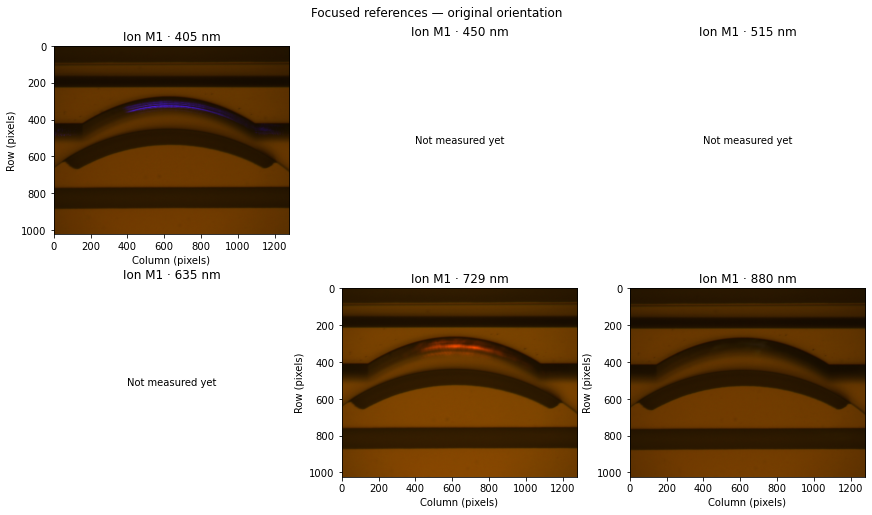

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(12, 7), constrained_layout=True)
for ax, wl in zip(axes.flat, WAVELENGTHS_NM):
    image = white_light[wl]
    ax.set_title(f"Ion {ION_INDEX} · {wl} nm")
    if image is None:
        ax.text(0.5, 0.5, "Not measured yet", ha="center", va="center", transform=ax.transAxes)
        ax.set_axis_off()
    else:
        ax.imshow(image, origin="upper", cmap="gray")
        ax.set(xlabel="Column (pixels)", ylabel="Row (pixels)")
fig.suptitle("Focused references — original orientation")
plt.show()

## Optional: load complete intensity stacks

Set `LOAD_FULL_STACKS = True` in Settings and rerun this cell to read every height plane into memory. For a single raw RGB frame at any acquisition index, use `scans[405].read_frame(frame_index=20)` instead. Loading a full stack leaves every source TIFF unchanged.

Scalar intensity follows the existing `Experimental_Import` convention: float32 **R + G + B**, avoiding uint8 overflow. No rotation, dark subtraction, exposure correction, or normalization has been applied. Corresponding heights and exposures are available as `scan.frames.height_um.to_numpy()` and `scan.frames.exposure_ms.to_numpy()` in the same order.

In [14]:
# Drop any earlier stacks before loading again.
intensity = dict.fromkeys(WAVELENGTHS_NM)
if LOAD_FULL_STACKS:
    for wl, scan in scans.items():
        if scan is not None:
            print(f"Loading ion {ION_INDEX}, {wl} nm ({len(scan.frames)} frames)...", flush=True)
            intensity[wl] = scan.load_intensity()
            print(f"  shape={intensity[wl].shape}; {intensity[wl].nbytes / 2**20:.1f} MiB")
else:
    print("Full stacks not allocated. Logs, references, and sample frames are loaded.")

Loading ion M1, 405 nm (88 frames)...
  shape=(88, 1024, 1280); 440.0 MiB
Loading ion M1, 729 nm (150 frames)...
  shape=(150, 1024, 1280); 750.0 MiB
Loading ion M1, 880 nm (150 frames)...
  shape=(150, 1024, 1280); 750.0 MiB


## Manual lens alignment — two points per wavelength

You choose **both points manually** on the original focused TIFF. Their joining line is rotated to horizontal. There is no automatic edge or corner detection. Click the same pair of physical lens features in each reference; click order does not matter. The midpoint of the two rotated points defines the lens origin, with x rightward and y upward.

The camera calibration below initially matches `Experimental_Import`: 5.3 µm camera pixels / 50× = **0.106 µm per image pixel**. This lateral calibration is separate from the 2:1 Z-stage ratio.

1. Run the alignment settings and `%matplotlib qt` cell. A window opens for each measured wavelength.
2. Click your two points with the left mouse button. A right click removes the most recent point before the second is selected. After the second point, the window closes and the next wavelength opens. Closing a window early cancels that wavelength without saving it; completed wavelengths are retained.
3. Run the inline preview cell and inspect the cyan line. Set `RESELECT_WAVELENGTHS = [405]` (or any desired list) and rerun alignment to replace a selection. Clear the list afterward.

Selections are saved independently as `ca_broadband_alignments/ion_M1_405_nm.json`, etc. Later runs reuse them. Changed reference files or camera calibration require reselection. The rotation uses the existing importer's cropped nearest-neighbor convention, keeping frame dimensions and pixel values. Both clicked points and the rotation are saved.

In [15]:
PIXEL_SIZE_UM = 5.3
MAGNIFICATION = 50.0
RESELECT_WAVELENGTHS = []  # e.g. [405] or [405, 729, 880] to choose again.
ALIGNMENT_DIR = PROJECT_ROOT / "Gen_1_Paper" / "ca_broadband_alignments"

In [16]:
%matplotlib qt

alignments = align_scans_manual(
    scans, ALIGNMENT_DIR,
    reselect=RESELECT_WAVELENGTHS,
    pixel_size_um=PIXEL_SIZE_UM, magnification=MAGNIFICATION,
)

M1, 405 nm: saved manual rotation 0.2176 degrees
M1, 729 nm: saved manual rotation 0.4351 degrees
M1, 880 nm: saved manual rotation 0.2897 degrees


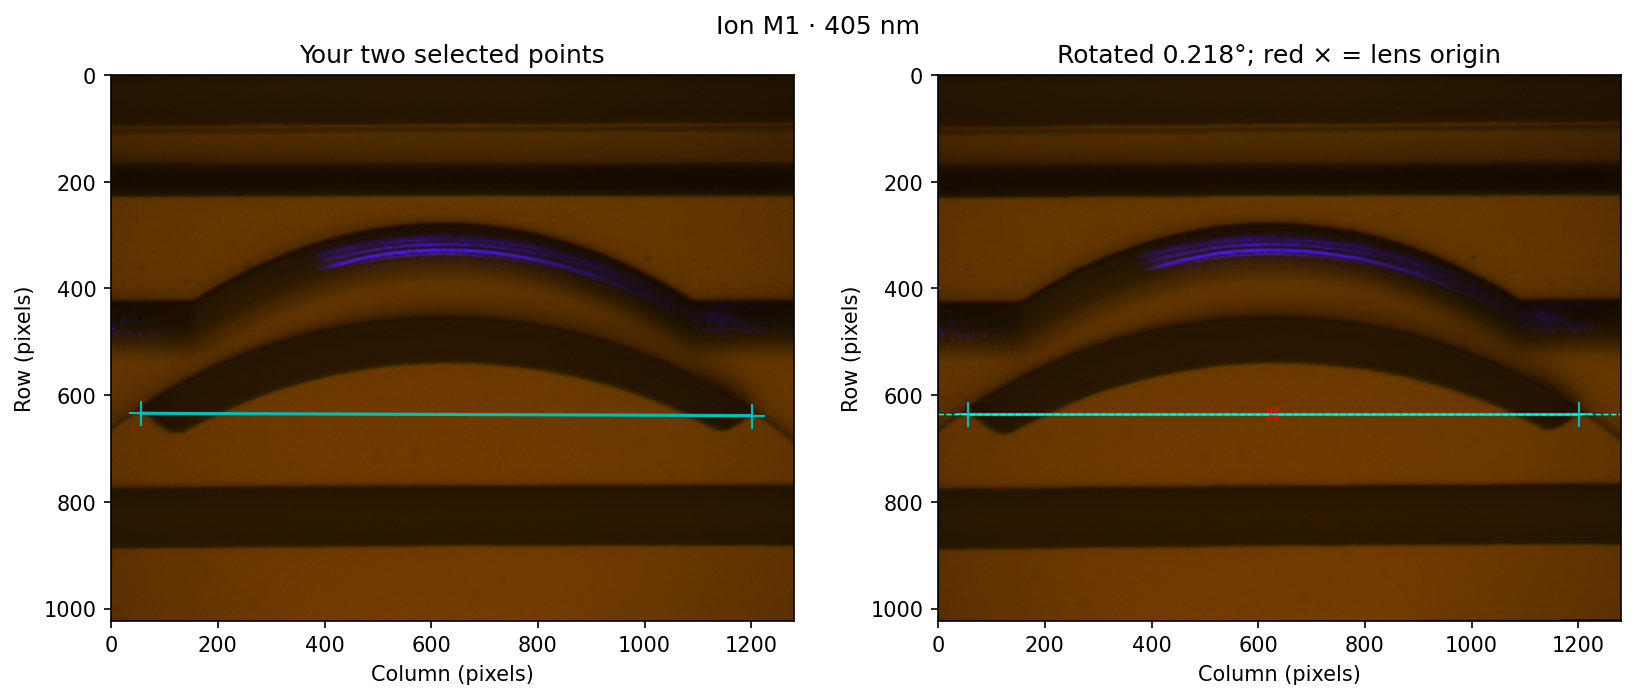

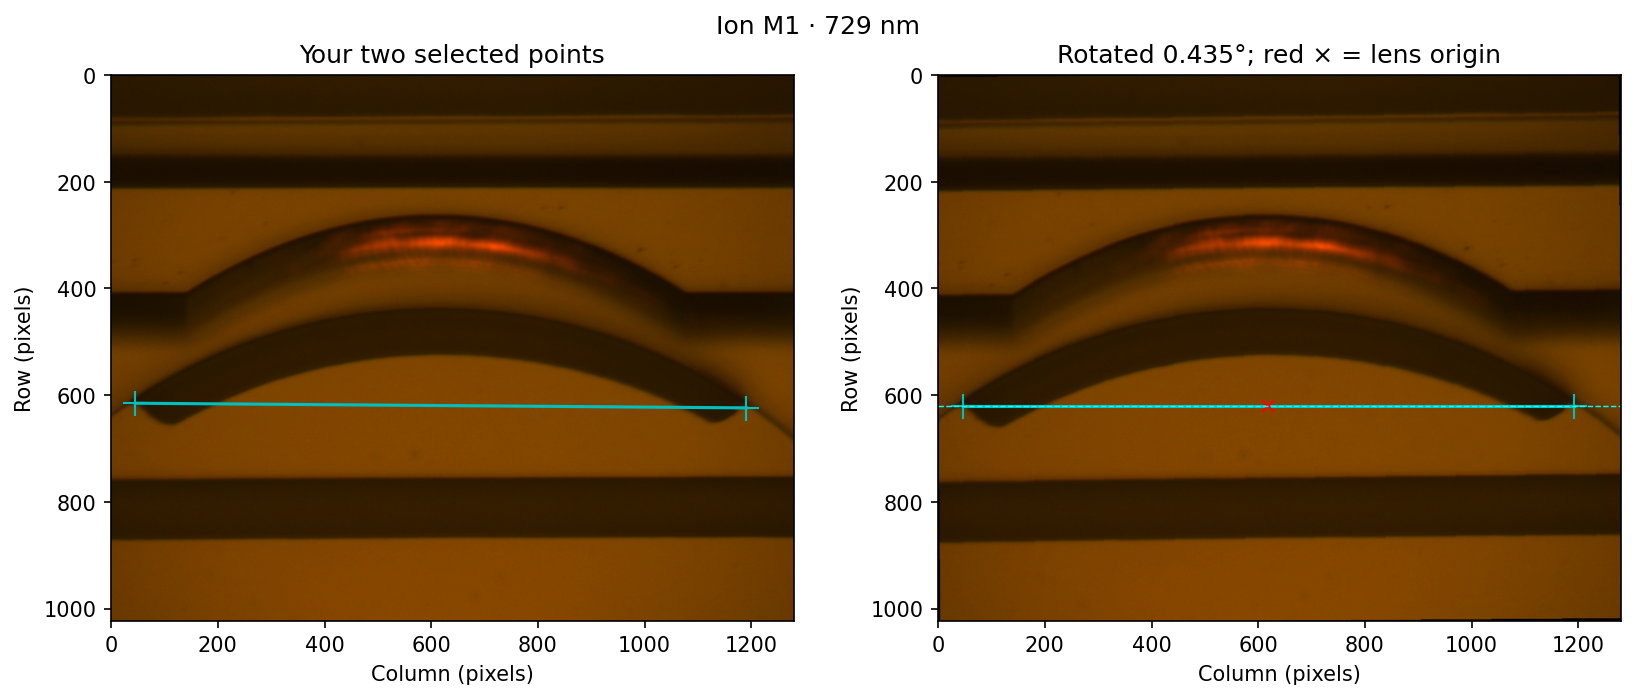

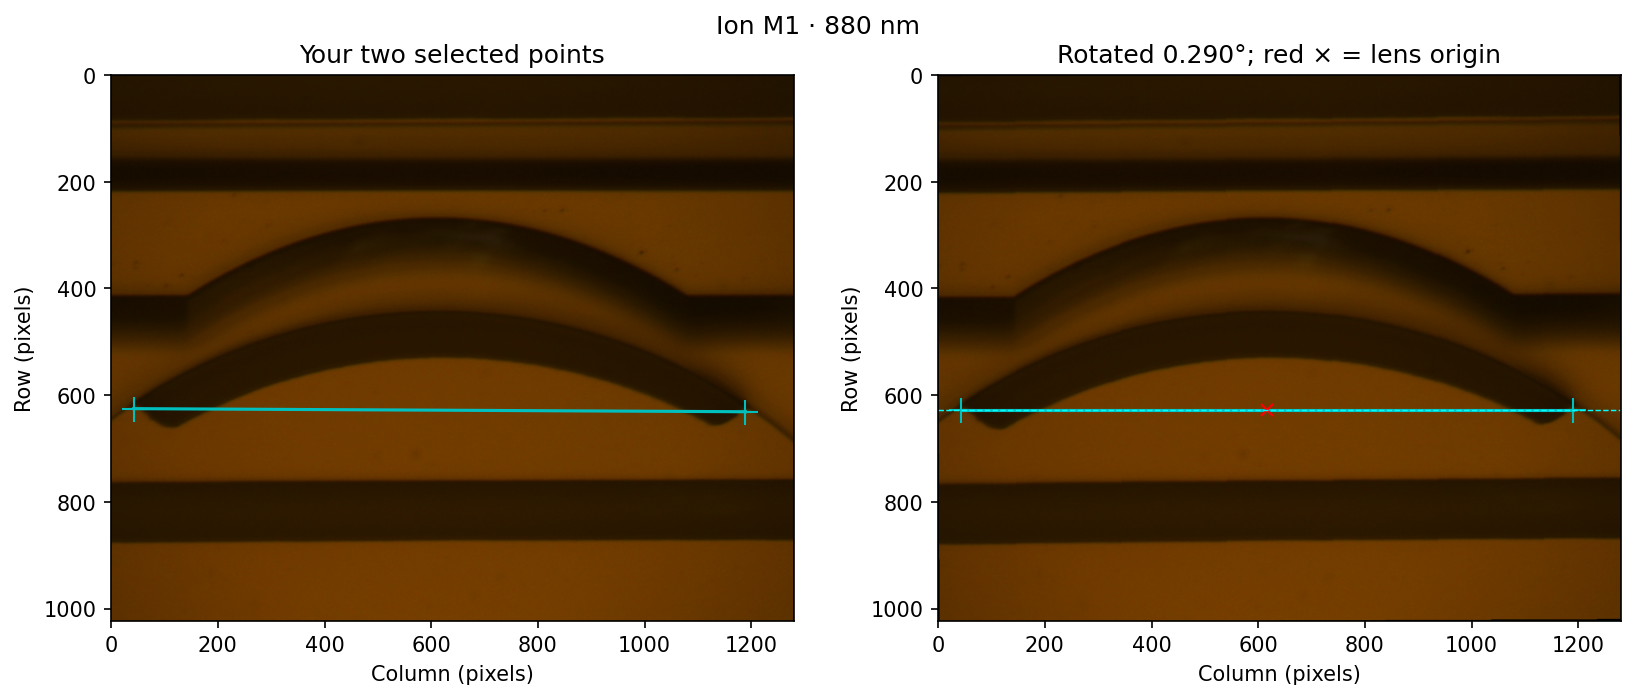

,wavelength_nm,angle_deg,manual_points_px,lens_origin_px
0,405,0.217578,"[[55.30055053086892, 633.9531655524972], [1200...","[628.3763381885185, 636.1707455539544]"
1,729,0.435149,"[[45.153165552496944, 615.108022021235], [1190...","[618.5761329180901, 619.6189303413745]"
2,880,0.289736,"[[42.25391270153352, 625.255406999607], [1188....","[616.1713720434013, 628.2741217012057]"


In [17]:
%matplotlib inline
%config InlineBackend.print_figure_kwargs = {"facecolor": "white", "edgecolor": "white", "transparent": False}

alignment_figures = preview_alignments(scans, alignments)
for figure in alignment_figures:
    display(figure)
    plt.close(figure)
display(pd.DataFrame([
    {"wavelength_nm": wl, "angle_deg": a["angle_deg"],
     "manual_points_px": a["points_px"], "lens_origin_px": a["origin_px"]}
    for wl, a in alignments.items() if a is not None
]))

## Choose the height and plot window

Choose a common `HEIGHT_UM` above the focused surface, or supply an entry in `HEIGHT_BY_WAVELENGTH_UM` to choose a different height for a wavelength. The nearest measured plane is selected **without interpolation**, within `MAX_HEIGHT_ERROR_UM`. The table and panel titles report the actual sampled height. A requested height beyond a scan's coverage raises a clear error instead of silently picking a distant plane. Currently the M1 405 nm scan ends at about 87.93 µm and the P1 405 nm scan ends at about 129.89 µm.

The plot uses a ±30 µm window centered separately on each beam's brightest pixel by default, matching the reference figure's layout. Lens-relative coordinates are preserved in the result. To exclude another bright feature or a hot pixel, give `PEAK_ROI_UM[wl] = (xmin, xmax, ymin, ymax)` in aligned lens coordinates. To set the center directly, use `CENTER_UM[wl] = (x, y)` instead. The alignment previews show the lens origin in red.

Each panel is normalized to its **own displayed maximum**, giving a 0–1 scale. No automatic background subtraction or exposure correction is applied; the figure compares normalized shapes. Optional `BACKGROUND_COUNTS[wl]` subtracts a user-specified scalar in raw R+G+B units before clipping to zero. Exposure times, subtraction, chosen centers, and normalization peaks are recorded in the export.

Use `GLOBAL_X_SHIFT_UM` and `GLOBAL_Y_SHIFT_UM` for a common translation of every image panel, after each beam is centered. Positive X moves the beams right, positive Y moves them up; for example `(5, -3)` moves every beam 5 µm right and 3 µm down inside the fixed ±30 µm axes. Change these values in the settings cell, then rerun the plot cell. Shifts are recorded in the export metadata and plotted x/y arrays.

In [41]:
HEIGHT_UM =75.0  # Physical height above focus; change this and rerun the next cell.
HEIGHT_BY_WAVELENGTH_UM = {}  # e.g. {405: 70.0}; others use HEIGHT_UM.
MAX_HEIGHT_ERROR_UM = 0.6
HALF_WIDTH_UM = 30.0
GLOBAL_X_SHIFT_UM = 0.0  # Positive moves every beam right; negative moves left.
GLOBAL_Y_SHIFT_UM = 15.0  # Positive moves every beam up; negative moves down.
SHOW_HEIGHTS = True
FONT_SIZE = 13

PEAK_ROI_UM = dict.fromkeys(WAVELENGTHS_NM)  # Optional lens-relative search rectangle.
CENTER_UM = dict.fromkeys(WAVELENGTHS_NM)    # Optional lens-relative (x, y) center.
BACKGROUND_COUNTS = {wl: 0.0 for wl in WAVELENGTHS_NM}

,ion_index,wavelength_nm,requested_height_um,selected_height_um,frame_index,exposure_ms,center_um,normalization_peak_counts
0,M1,405,75.0,74.9375,74,3.892059,"[3.352108152017039, 13.374099028719161]",215.0
1,M1,729,75.0,74.9340,74,3.373962,"[1.7409299106824452, 34.51560661618569]",231.0
2,M1,880,75.0,74.9410,74,33.313552,"[4.221834563399458, 33.2070569003278]",536.0


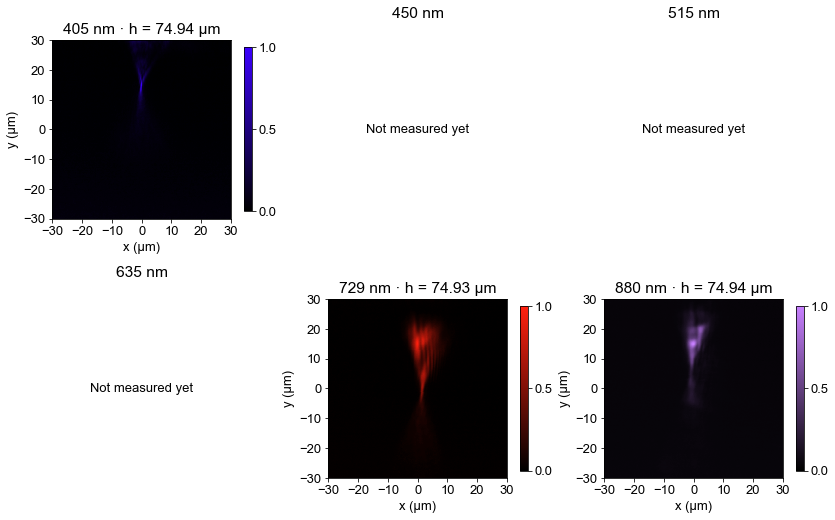

In [42]:
# Display with an opaque white canvas, including in a dark notebook theme.
%config InlineBackend.print_figure_kwargs = {"facecolor": "white", "edgecolor": "white", "transparent": False}

from importlib import reload
import Analysis.ca_3d_plotting as ca_plotting
plot_publication_grid = reload(ca_plotting).plot_publication_grid

# Always read the selected source frame, avoiding a stale stack if ION_INDEX changed.
planes = dict.fromkeys(WAVELENGTHS_NM)
for wl, scan in scans.items():
    if scan is None:
        continue
    if alignments.get(wl) is None:
        raise RuntimeError(f"Complete manual alignment for {wl} nm first.")
    planes[wl] = select_height_plane(
        scan, alignments[wl], HEIGHT_BY_WAVELENGTH_UM.get(wl, HEIGHT_UM),
        max_height_error_um=MAX_HEIGHT_ERROR_UM,
        center_um=CENTER_UM[wl], peak_roi_um=PEAK_ROI_UM[wl],
        background_counts=BACKGROUND_COUNTS[wl],
    )

if "publication_figure" in globals():
    plt.close(publication_figure)
publication_figure, publication_metadata, publication_arrays = plot_publication_grid(
    planes, half_width_um=HALF_WIDTH_UM, font_size=FONT_SIZE, show_heights=SHOW_HEIGHTS,
    x_shift_um=GLOBAL_X_SHIFT_UM, y_shift_um=GLOBAL_Y_SHIFT_UM,
)
display(publication_metadata[[
    "ion_index", "wavelength_nm", "requested_height_um", "selected_height_um",
    "frame_index", "exposure_ms", "center_um", "normalization_peak_counts",
]])
display(publication_figure)
plt.close(publication_figure)

## Export publication figure and plotted data

Run this cell when the alignment and height look right. Exports include a 600 dpi PNG, vector PDF/SVG with raster image panels, an NPZ with the exact cropped raw/normalized intensity and x/y axes, and a JSON with acquisition and processing metadata including all manual alignment points. Missing wavelengths remain labeled placeholders. Reusing the same `EXPORT_STEM` replaces that export; change it to keep another version.

In [20]:
# OUTPUT_DIR = PROJECT_ROOT / "Gen_1_Paper" / "ca_broadband_results"
# EXPORT_STEM = f"ca_broadband_ion_{ION_INDEX}_height_{HEIGHT_UM:g}um"
# exported_paths = export_publication(
#     publication_figure, publication_metadata, publication_arrays, OUTPUT_DIR, EXPORT_STEM,
# )
# for path in exported_paths:
#     print(path.relative_to(PROJECT_ROOT))

## Peak count rate versus height

For every measured frame, calculate

`peak_count_rate_per_s = max_over_pixels(R + G + B) / (exposure_ms / 1000)`

This is the brightest **single-pixel camera count rate**, in counts/s. Use the original full frame so rotation or cropping cannot discard a maximum; no manual alignment is needed for this calculation. There is no smoothing, background subtraction, or normalization to a curve's own maximum. Heights use each wavelength's focused zero and the 2:1 stage ratio, as above.

Each wavelength retains its own measured height range and vertical count-rate scale. These camera counts are exposure-normalized, but have not been corrected for wavelength-dependent camera response or input laser power. A circle marks the largest measured rate in each curve; the table lists that plane's actual height, frame index, exposure, and peak counts.

Run the calculation cell once after importing `scans`; it reads one TIFF at a time. Then rerun just the plot cell to change between `"linear"` and `"log"` display. The DataFrames in `peak_rate_tables` preserve all per-frame values and peak pixel coordinates.

In [ ]:
from importlib import reload
import Analysis.ca_3d_import as ca_import
import Analysis.ca_3d_plotting as ca_plotting
peak_count_rate_vs_height = reload(ca_import).peak_count_rate_vs_height
plot_peak_count_rates = reload(ca_plotting).plot_peak_count_rates

peak_rate_tables = dict.fromkeys(WAVELENGTHS_NM)
for wl, scan in scans.items():
    if scan is None:
        continue
    print(f"Ion {scan.ion_index}, {wl} nm: calculating peak rates for {len(scan.frames)} frames...", flush=True)
    peak_rate_tables[wl] = peak_count_rate_vs_height(scan)
peak_rate_data = pd.concat(
    [table for table in peak_rate_tables.values() if table is not None], ignore_index=True,
)
print(f"Calculated {len(peak_rate_data)} frame rates.")

Calculated 388 frame rates for ion M1.


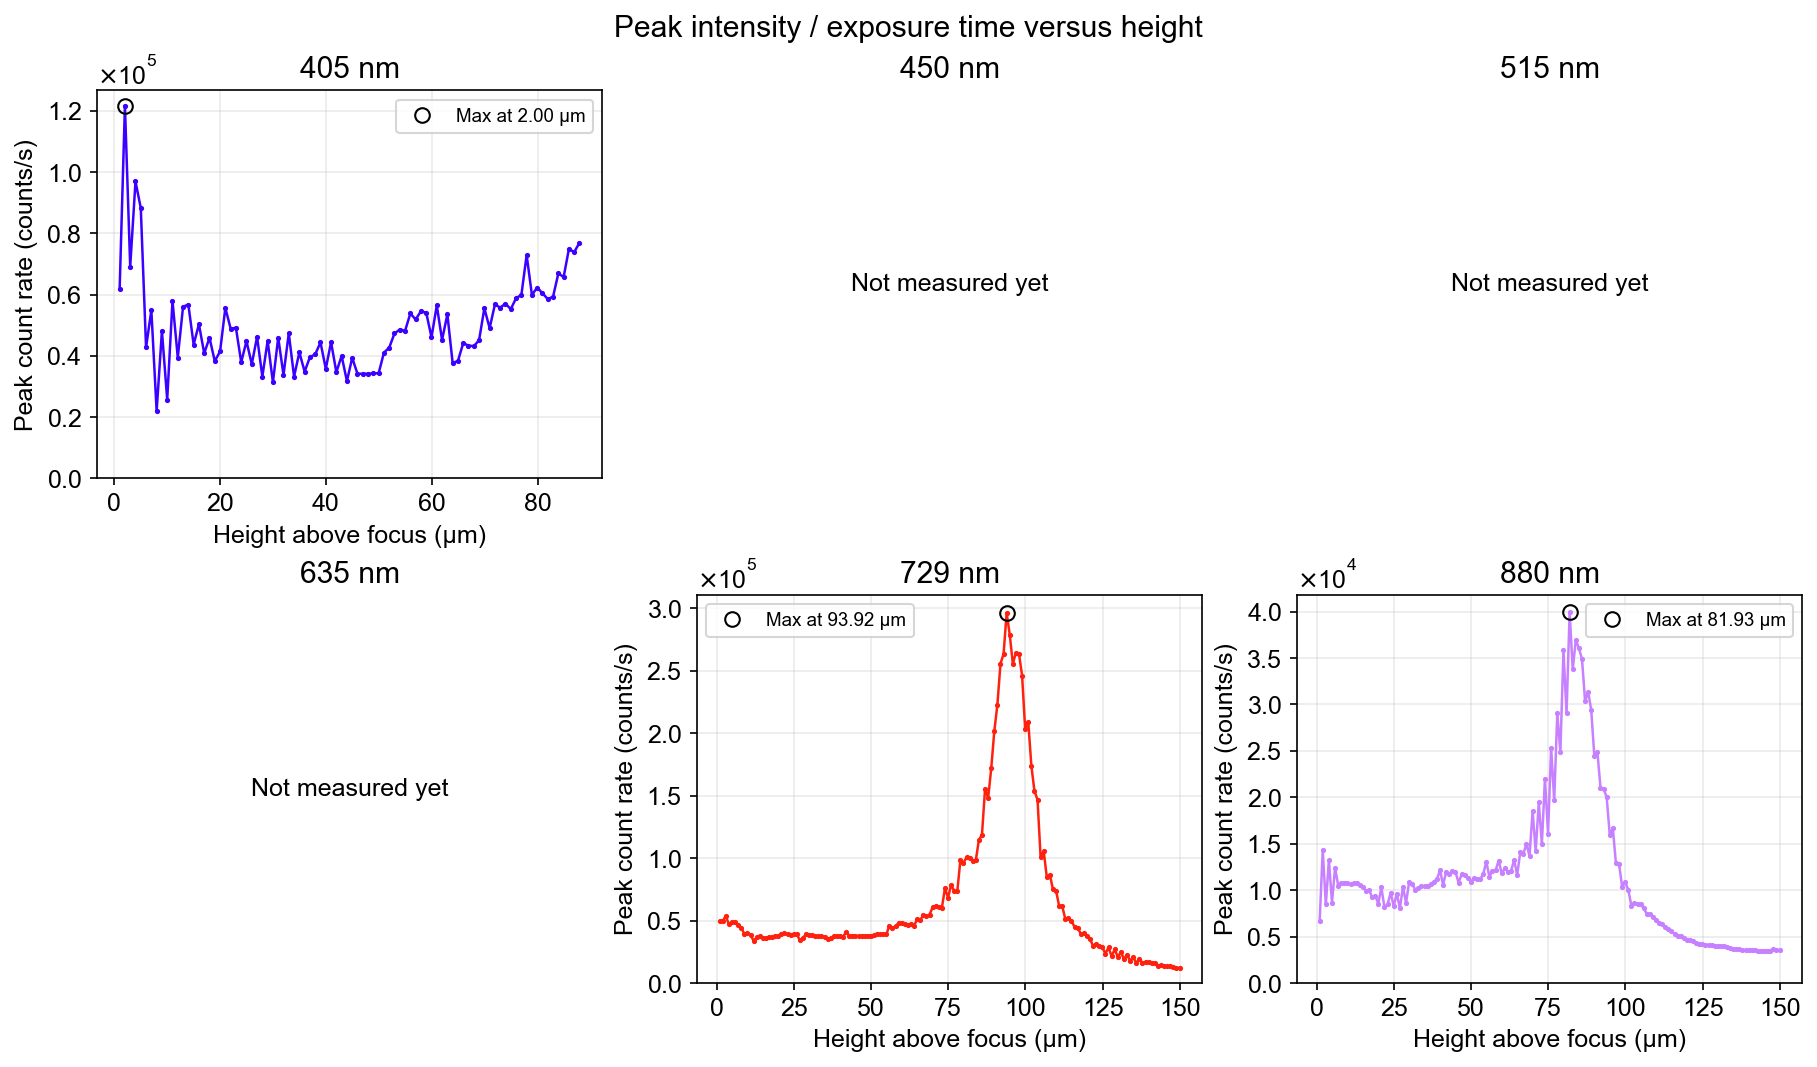

,ion_index,wavelength_nm,height_um,image_index,exposure_ms,peak_counts,peak_count_rate_per_s
0,M1,405,2.0020,1,1.864980,227.0,121717.103588
1,M1,729,93.9170,93,0.796141,236.0,296429.743645
2,M1,880,81.9315,81,13.889277,555.0,39958.883869


In [ ]:
%matplotlib inline
%config InlineBackend.print_figure_kwargs = {"facecolor": "white", "edgecolor": "white", "transparent": False}

RATE_Y_SCALE = "linear"  # "linear" or "log"; rates remain in counts/s.
if "peak_rate_figure" in globals():
    plt.close(peak_rate_figure)
peak_rate_figure, peak_rate_maxima = plot_peak_count_rates(
    peak_rate_tables, y_scale=RATE_Y_SCALE,
)
display(peak_rate_figure)
plt.close(peak_rate_figure)
display(peak_rate_maxima[[
    "ion_index", "wavelength_nm", "height_um", "image_index",
    "exposure_ms", "peak_counts", "peak_count_rate_per_s",
]])

In [ ]:
# Optional: export the plotted rates and their figure.
# RATE_OUTPUT_DIR = PROJECT_ROOT / "Gen_1_Paper" / "ca_broadband_results"
# RATE_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
# RATE_STEM = f"ca_peak_count_rate_ion_{ION_INDEX}"
# peak_rate_data.to_csv(RATE_OUTPUT_DIR / f"{RATE_STEM}.csv", index=False)
# for extension in ("png", "pdf", "svg"):
#     peak_rate_figure.savefig(
#         RATE_OUTPUT_DIR / f"{RATE_STEM}.{extension}", dpi=600,
#         bbox_inches="tight", facecolor="white", transparent=False,
#     )